# 11 · Planner view: where to stage for a shift

What a planner sees when a shift starts: the production model's forecast for the shift's first hour, made with the data on record at that moment, for each of the 77 community areas, on a map, with the 10 areas to stage in. The forecast refreshes every hour, so units can be moved during the shift. Afterwards, once the hours are labelled, how many of the shift's crashes fell in those 10 areas (the shift's P0), and how that compares with ranking by the 8 hourly forecasts summed, which is only complete when the shift ends.

Change `DAY` and `SHIFT_START` to look at another shift (shifts start at 00:00, 08:00 and 16:00).

In [1]:
import json
import os
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# run from the repo root, where main.py, config/ and datamart/ are
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from utils.tables import read_table

with open("config/pipeline.yaml") as f:
    config = yaml.safe_load(f)

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from shapely.geometry import shape

DAY, SHIFT_START = "2023-06-16", 16   # a Friday evening shift, 16:00 to 24:00
k, hours = config["evaluation"]["top_k"], config["evaluation"]["shift_hours"]
first = pd.Timestamp(f"{DAY} {SHIFT_START:02d}:00")
last = first + timedelta(hours=hours)
print(f"shift {first:%a %d %b %Y %H:%M} to {last:%H:%M}; the top {k} areas")

shift Fri 16 Jun 2023 16:00 to 00:00; the top 10 areas


## 1 · The forecast for each area

In [2]:
predictions = read_table("model_predictions", config, filters=[("date", "==", DAY), ("role", "==", "production")])
shift = predictions[(predictions["hour_start"] >= first) & (predictions["hour_start"] < last)]
print(f"production model: {', '.join(shift['model_version'].unique())}; {shift['hour_start'].nunique()} hours forecast")

with open(os.path.join(config["paths"]["reference"], config["sources"]["boundaries"]["file"])) as f:
    areas = json.load(f)["features"]
names = {int(a["properties"]["area_numbe"]): a["properties"]["community"].title() for a in areas}

# at the shift's start only its first hour has a forecast: the later hours are forecast during the shift
forecast = shift[shift["hour_start"] == first].set_index("community_area")["predicted_count"].rename("forecast").to_frame()
forecast["area"] = forecast.index.map(names)
forecast = forecast.sort_values("forecast", ascending=False, kind="stable")
forecast["rank"] = range(1, len(forecast) + 1)
forecast.head(k).round(2)

production model: M2_2021_12_20261027T163527; 8 hours forecast


,forecast,area,rank
community_area,,,
8,0.96,Near North Side,1
28,0.94,Near West Side,2
32,0.81,Loop,3
25,0.72,Austin,4
19,0.70,Belmont Cragin,5
22,0.69,Logan Square,6
24,0.61,West Town,7
44,0.57,Chatham,8
2,0.54,West Ridge,9


## 2 · The map

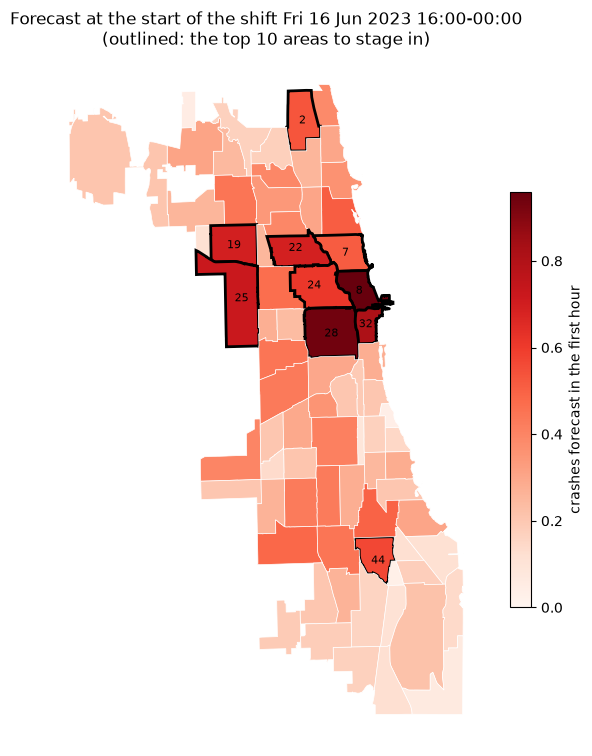

In [3]:
top = set(forecast.index[:k])
norm = Normalize(vmin=0, vmax=forecast["forecast"].max())
fig, ax = plt.subplots(figsize=(7, 9))
for a in areas:
    number = int(a["properties"]["area_numbe"])
    geometry = shape(a["geometry"])
    for polygon in getattr(geometry, "geoms", [geometry]):
        x, y = polygon.exterior.xy
        ax.fill(x, y, color=plt.cm.Reds(norm(forecast.loc[number, "forecast"])),
                edgecolor="black" if number in top else "white", linewidth=2 if number in top else 0.5)
    if number in top:
        point = geometry.representative_point()
        ax.annotate(str(number), (point.x, point.y), ha="center", va="center", fontsize=8)
fig.colorbar(ScalarMappable(norm=norm, cmap="Reds"), ax=ax, shrink=0.6, label="crashes forecast in the first hour")
ax.set_title(f"Forecast at the start of the shift {first:%a %d %b %Y %H:%M}-{last:%H:%M}\n(outlined: the top {k} areas to stage in)")
ax.set_axis_off()
plt.show()

## 3 · How did the shift go?

The labels: crashes that occurred in the shift's hours, as the label store has them. P0 for this one shift: the share of them in the 10 outlined areas. For comparison, the 10 areas with the highest forecast summed over the shift's 8 hours: that ranking uses forecasts made during the shift, so it is a summary after the event, not something the planner had at the start.

In [4]:
labels = read_table("label_store", config, filters=[("date", "==", DAY)])
labels = labels[(labels["hour_start"] >= first) & (labels["hour_start"] < last)]
labels = labels.sort_values("label_snapshot_date").drop_duplicates(["community_area", "hour_start"], keep="last")
actual = labels.groupby("community_area")["crash_count"].sum()
forecast["actual"] = actual.reindex(forecast.index, fill_value=0)
forecast["summed"] = shift.groupby("community_area")["predicted_count"].sum()
total, caught = forecast["actual"].sum(), forecast.loc[forecast.index[:k], "actual"].sum()
summed_top = forecast.sort_index().sort_values("summed", ascending=False, kind="stable").index[:k]
caught_summed = forecast.loc[summed_top, "actual"].sum()
print(f"crashes in the shift: {total}; in the top {k} areas at the start: {caught} (P0 {caught / total:.2f}); "
      f"by the 8 hours summed: {caught_summed} (P0 {caught_summed / total:.2f}); forecast citywide: {forecast['summed'].sum():.1f}")
forecast.head(k).round(2)

crashes in the shift: 112; in the top 10 areas at the start: 28 (P0 0.25); by the 8 hours summed: 27 (P0 0.24); forecast citywide: 126.0


,forecast,area,rank,actual,summed
community_area,,,,,
8,0.96,Near North Side,1,2,5.83
28,0.94,Near West Side,2,3,4.92
32,0.81,Loop,3,5,4.57
25,0.72,Austin,4,3,3.59
19,0.70,Belmont Cragin,5,1,3.36
22,0.69,Logan Square,6,2,3.35
24,0.61,West Town,7,4,3.23
44,0.57,Chatham,8,4,2.86
2,0.54,West Ridge,9,3,2.48


## 4 · Every shift of the replay: staged at the start, and summed after

The same two rankings for every shift from 4 January (from then on both B0 and M2 forecast every hour, one in production, one in shadow). P0 as monitored and as the models were selected on is the second one, the 8 hourly forecasts summed; the first is what a planner could act on at the start of the shift.

In [5]:
predictions = read_table("model_predictions", config, filters=[("date", ">=", "2023-01-04")])
labels = read_table("label_store", config, filters=[("date", ">=", "2023-01-04")])
labels = labels.sort_values("label_snapshot_date").drop_duplicates(["community_area", "hour_start"], keep="last")
replay = predictions.assign(model=predictions["model_version"].str[:2]).merge(
    labels[["community_area", "hour_start", "crash_count"]], on=["community_area", "hour_start"])
replay = replay[replay["model"].isin(["B0", "M2"])]
replay["shift"] = replay["hour_start"].dt.floor(f"{hours}h")

rows = []
for (model, start), s in replay.groupby(["model", "shift"]):
    if s["hour_start"].nunique() < hours or s["crash_count"].sum() == 0:
        continue   # a shift not complete in the replay, or with no crash
    area = s.groupby("community_area").agg(actual=("crash_count", "sum"), summed=("predicted_count", "sum"))
    area["at_start"] = s[s["hour_start"] == start].set_index("community_area")["predicted_count"]
    row = {"model": model, "month": f"{start:%Y-%m}"}
    for by in ["at_start", "summed"]:
        top = area.sort_values(by, ascending=False, kind="stable").head(k)   # ties: lower area number first
        row[by] = top["actual"].sum() / area["actual"].sum()
    rows.append(row)
shifts = pd.DataFrame(rows)
print(f"shifts: {shifts.groupby('model').size().to_dict()}")
print(shifts.groupby("model")[["at_start", "summed"]].mean().round(3))
shifts.pivot_table(index="month", columns="model", values=["at_start", "summed"]).round(3)

shifts: {'B0': 716, 'M2': 716}
       at_start  summed
model                  
B0        0.233   0.288
M2        0.305   0.314


at_start        summed       
model         B0     M2     B0     M2
month                                
2023-01    0.225  0.296  0.279  0.299
2023-02    0.230  0.295  0.277  0.298
2023-03    0.212  0.304  0.281  0.312
2023-04    0.223  0.294  0.276  0.311
2023-05    0.245  0.305  0.293  0.311
2023-06    0.245  0.313  0.295  0.324
2023-07    0.241  0.321  0.303  0.327
2023-08    0.240  0.314  0.298  0.327